# Referee Decision Triage on IBM LinuxONE
**IBM Z Datathon 2026**

Referee assessors cannot review every incident in every match. This notebook trains a model that learns how the league *typically* calls each kind of incident, then scores how surprising each real decision was. Assessors review the most unusual calls first.

**Data:** StatsBomb Open Data, Premier League 2015/16 (380 matches, 24,957 incidents). Built in `01_data_prep.ipynb`.
**Labels:** `no_foul` (clean tackles), `foul` (no card), `yellow` (second yellows counted as yellow, since the foul itself was yellow-level), `red`.
**Split:** fixed stratified 80/20 train/test (`split` column), shared by the whole team so results are comparable.

Everything below runs on our LinuxONE Community Cloud instance (s390x) inside the IBM Jupyter Lab ML container.

## 1. Referee consistency check

First question: do some referees simply give more cards than others? We compare the card rate per foul for referees with 100+ fouls, and home vs away.

In [1]:
import pandas as pd
df = pd.read_csv("data/incidents_pl1516.csv")

fouls = df[df["label"] != "no_foul"].copy()
fouls["card"] = fouls["label"].isin(["yellow", "red"]).astype(int)

by_ref = (fouls.groupby("referee")
          .agg(fouls=("card", "size"), card_rate=("card", "mean"))
          .sort_values("card_rate"))
by_ref[by_ref["fouls"] >= 100]

,fouls,card_rate
referee,,
Lee Mason,554,0.086643
Paul Tierney,108,0.092593
Roger East,636,0.097484
Robert Madley,631,0.098257
Mike Jones,674,0.102374
Anthony Taylor,818,0.106357
Martin Atkinson,748,0.108289
Craig Pawson,708,0.108757
Jonathan Moss,622,0.112540


In [2]:
fouls.groupby("is_home")["card"].agg(["size", "mean"])

,size,mean
is_home,,
0,5060,0.115217
1,4452,0.109164


Card rates range from 8.7% (Lee Mason) to 15.0% (Andre Marriner). Home vs away card rates barely differ (10.9% vs 11.5%). Away teams do get called for more fouls (5,060 vs 4,452), but this data can't separate referee bias from away teams simply defending more.

Is the spread between referees real, or just chance? A chi-square test across all referees:

In [3]:
from scipy.stats import chi2_contingency
chi2, p, dof, _ = chi2_contingency(pd.crosstab(fouls["referee"], fouls["card"]))
print(f"p-value: {p:.5f}")

p-value: 0.14672


**p = 0.15: not significant.** With 15 referees, the gap between the most and least strict can easily appear by chance. So "referee X is biased" is *not* our claim. Instead the tool works at the level of **individual decisions**: which specific calls are unusual for their context.

## 2. Where cards happen

In [4]:
!pip install mplsoccer


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


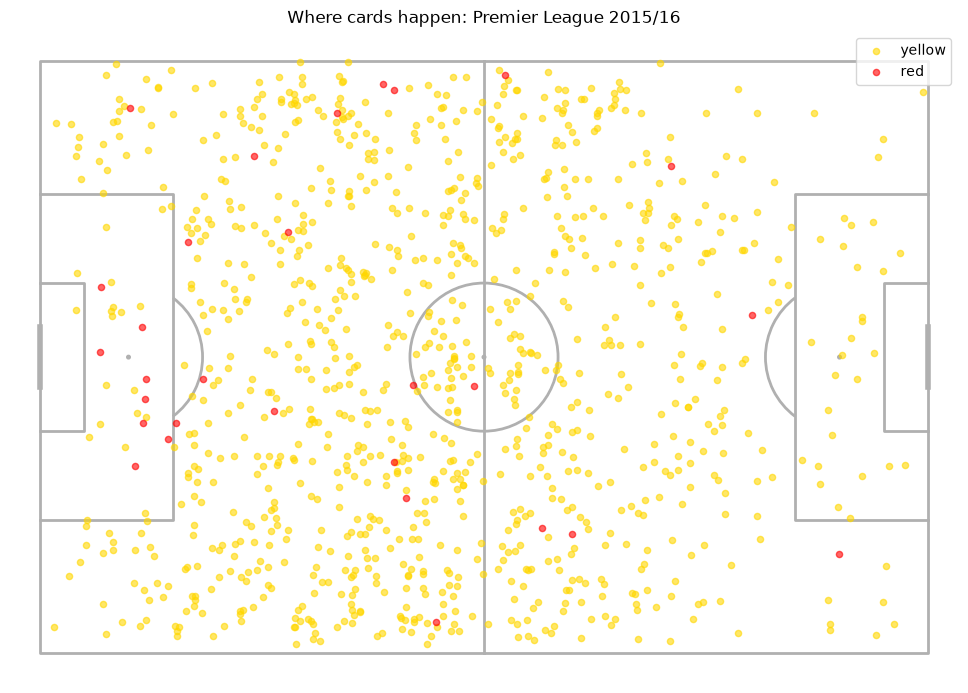

In [7]:
from mplsoccer import Pitch
import matplotlib.pyplot as plt

pitch = Pitch(pitch_type="statsbomb")
fig, ax = pitch.draw(figsize=(10, 7))

cards = df[df["label"].isin(["yellow", "red"])]
for lab, color in {"yellow": "gold", "red": "red"}.items():
    s = cards[cards["label"] == lab]
    pitch.scatter(s["x"], s["y"], ax=ax, c=color, s=20, alpha=0.6, label=lab)

ax.legend()
ax.set_title("Where cards happen: Premier League 2015/16")
plt.show()

In [8]:
fig.savefig("data/cards_pitch.png", dpi=200, bbox_inches="tight")

StatsBomb coordinates always have the fouling player's team attacking left to right, so the left half is their own half. Most cards happen there, and red cards cluster in and around the player's own box, which matches the rule on denying an obvious goal-scoring opportunity.

## 3. Model

**Features** (only ones that exist for both fouls and tackles): minute, period, x/y location, home/away, player position, play pattern, and fouls the player and team committed earlier in the match.

**Model:** XGBoost multiclass with *no* class weights. Class weights would make red cards look artificially common and distort the probabilities, and the surprise score below needs honest probabilities.

In [20]:
df = df.sort_values(["match_id", "period", "minute", "second"]).reset_index(drop=True)
is_f = (df["label"] != "no_foul").astype(int)
df["player_fouls_before"] = is_f.groupby([df["match_id"], df["player"]]).cumsum() - is_f
df["team_fouls_before"] = is_f.groupby([df["match_id"], df["team"]]).cumsum() - is_f

In [22]:
import numpy as np
import xgboost as xgb
from sklearn.metrics import classification_report

classes = ["no_foul", "foul", "yellow", "red"]
y = df["label"].map({c: i for i, c in enumerate(classes)})

feats = ["minute", "period", "x", "y", "is_home", "position", "play_pattern",
         "player_fouls_before", "team_fouls_before"]
X = pd.get_dummies(df[feats], columns=["position", "play_pattern"], dtype=int)

tr = df["split"] == "train"
te = df["split"] == "test"

model = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                          objective="multi:softprob", eval_metric="mlogloss")
model.fit(X[tr], y[tr])

pred = model.predict(X[te])
print(classification_report(y[te], pred, target_names=classes, zero_division=0))

              precision    recall  f1-score   support

     no_foul       0.69      0.85      0.76      3089
        foul       0.55      0.38      0.45      1689
      yellow       0.00      0.00      0.00       208
         red       0.00      0.00      0.00         6

    accuracy                           0.66      4992
   macro avg       0.31      0.31      0.30      4992
weighted avg       0.61      0.66      0.62      4992



The model picks up real signal for foul vs no foul, but almost never predicts yellow or red. That is expected: what decides a card is the physical contact, which event data doesn't record. F1 isn't the right metric for our use case anyway; what matters is whether the **probabilities** are informative (section 4).

### Leak check

Our first model scored ~0.99 F1 on foul vs no foul, which was too good to be true. Inspecting feature importance and per-class averages, we found `under_pressure` was **always 1 for tackles and almost always 0 for fouls**: a data-logging artifact from how StatsBomb records events, not anything about football. The model had learned "under pressure = tackle". We removed the feature; the honest no-foul F1 is 0.76.

The table below (on the full dataset) shows the artifact. The importances above are from the corrected model.

In [24]:
pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

position_Center Forward         0.084486
x                               0.083249
play_pattern_Regular Play       0.063205
play_pattern_From Counter       0.059499
play_pattern_From Corner        0.038255
position_Left Center Forward    0.035779
play_pattern_From Keeper        0.031920
position_Right Center Back      0.026774
y                               0.026757
position_Goalkeeper             0.025425
dtype: float32

In [25]:
check = df.assign(x_entero=(df["x"] % 1 == 0))
check.groupby("label")[["under_pressure", "x", "y", "minute", "x_entero"]].mean()

,under_pressure,x,y,minute,x_entero
label,,,,,
foul,0.005093,62.280836,40.537570,46.593983,0.104584
no_foul,1.000000,43.098310,40.338336,46.542052,0.098867
red,0.000000,39.868966,37.572414,62.413793,0.103448
yellow,0.000962,53.210673,41.432115,55.461538,0.086538


## 4. Surprise score

For each incident: `surprise = -log( P(model gives to the referee's actual call) / base rate of that call )`.

Dividing by the base rate matters. Without it, every red card would rank as "surprising" just because reds are rare. With it, a call is surprising only if it was *less likely than usual for its type* in that specific context.

In [23]:
proba = model.predict_proba(X)
prior = y[tr].value_counts(normalize=True)
df["p_actual"] = proba[np.arange(len(df)), y.values]
df["prior"] = y.map(prior)
df["surprise"] = -np.log(df["p_actual"] / df["prior"])

flags = df[te].sort_values("surprise", ascending=False)
flags[["match_id", "minute", "player", "referee", "label", "p_actual", "prior"]].head(10)

,match_id,minute,player,referee,label,p_actual,prior
6282,3754068,81,Jordan Amavi,Martin Atkinson,yellow,0.002898,0.041673
9094,3754110,7,Carl Jenkinson,Craig Pawson,foul,0.034866,0.338292
12816,3754166,92,José Leonardo Ulloa,Jonathan Moss,no_foul,0.064321,0.618883
5355,3754054,67,Sebastián Coates Nión,Anthony Taylor,foul,0.042164,0.338292
19619,3754269,2,Ashley Williams,Robert Madley,foul,0.042610,0.338292
2983,3754016,78,Virgil van Dijk,Robert Madley,foul,0.044901,0.338292
1512,3753994,73,Adrian Mariappa,Michael Oliver,foul,0.045535,0.338292
1535,3753995,11,Ramires Santos do Nascimento,Robert Madley,foul,0.047328,0.338292
17146,3754231,85,Riyad Mahrez,Mark Clattenburg,no_foul,0.093503,0.618883
3382,3754023,0,Max-Alain Gradel,Neil Swarbrick,yellow,0.006453,0.041673


### Are the probabilities informative?

Compared to a baseline that only knows class frequencies:

In [26]:
from sklearn.metrics import log_loss, roc_auc_score
base = np.tile(prior.sort_index().values, (te.sum(), 1))
print("model log loss:   ", log_loss(y[te], proba[te.values], labels=[0, 1, 2, 3]))
print("baseline log loss:", log_loss(y[te], base, labels=[0, 1, 2, 3]))

fte = te & (y >= 1)
card = (y[fte] >= 2).astype(int)
print("card vs no card AUC (fouls only):", roc_auc_score(card, proba[fte.values][:, 2:].sum(1)))

model log loss:    0.7228164672851562
baseline log loss: 0.8041745887464806
card vs no card AUC (fouls only): 0.636261018243389


- **Log loss 0.723 vs 0.804 baseline** (~10% better): the probabilities carry real information, which is what the surprise score relies on.
- **Card vs no card AUC among fouls: 0.64** (0.5 = chance). Modest but real, and about what you'd expect without seeing the contact.

## 5. Speed on LinuxONE

In [27]:
import time
t0 = time.perf_counter()
model.predict_proba(X)
t = time.perf_counter() - t0
print(f"{len(X):,} incidents scored in {t:.3f}s = {len(X)/t:,.0f} incidents/sec on LinuxONE")

24,957 incidents scored in 0.158s = 157,968 incidents/sec on LinuxONE


A full season scored in a fraction of a second. Note: a model this size is also fast on a laptop. This shows the tool works in **real time on LinuxONE**, not that LinuxONE is faster than other hardware.

## 6. Export for the dashboard

In [29]:
model.save_model("data/model.json")
pd.Series(X.columns).to_csv("data/model_columns.csv", index=False)
flags[["id", "match_id", "minute", "second", "player", "team", "referee",
       "x", "y", "label", "p_actual", "prior", "surprise"]].to_csv("data/flagged_test.csv", index=False)

In [30]:
for i, c in enumerate(classes):
    df[f"p_{c}"] = proba[:, i]
df["model_pred"] = [classes[i] for i in proba.argmax(1)]

out = (df[te].sort_values("surprise", ascending=False)
       .rename(columns={"label": "referee_call"}))
out[["id", "match_id", "period", "minute", "second", "player", "team", "home_team", "away_team",
     "referee", "position", "play_pattern", "x", "y", "referee_call", "model_pred",
     "p_no_foul", "p_foul", "p_yellow", "p_red", "surprise"]].to_csv("data/dashboard_incidents.csv", index=False)
print(len(out))

4992


`dashboard_incidents.csv` holds the 4,992 **test** incidents (never seen in training), sorted by surprise, with all four probabilities, the referee's call and the model's prediction.

## 7. Live match replay (real-time demo)

Newcastle vs Tottenham (match 3754333). We **retrain without this match** so the demo uses a game the model has never seen, then score its incidents one by one in chronological order, as if live. An incident is flagged when its surprise is in the top 5% of the test set.

In [31]:
DEMO = 3754333

tr_demo = tr & (df["match_id"] != DEMO)
model_demo = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                               objective="multi:softprob", eval_metric="mlogloss")
model_demo.fit(X[tr_demo], y[tr_demo])
prior_demo = y[tr_demo].value_counts(normalize=True).sort_index().values

THRESH = df.loc[te, "surprise"].quantile(0.95)
demo = df[df["match_id"] == DEMO].sort_values(["period", "minute", "second"])
print(demo["home_team"].iloc[0], "vs", demo["away_team"].iloc[0], "| ref:", demo["referee"].iloc[0])
print(len(demo), "incidents | flag threshold:", round(THRESH, 2))

Newcastle United vs Tottenham Hotspur | ref: Anthony Taylor
61 incidents | flag threshold: 0.6


In [33]:
import time
rows = []
for idx, r in demo.iterrows():
    t0 = time.perf_counter()
    p = model_demo.predict_proba(X.loc[[idx]])[0]
    ms = (time.perf_counter() - t0) * 1000

    actual = classes.index(r["label"])
    s = -np.log(p[actual] / prior_demo[actual])
    flag = s > THRESH
    rows.append({"id": r["id"], "minute": r["minute"], "player": r["player"], "team": r["team"],
                 "referee_call": r["label"], "model_pred": classes[p.argmax()],
                 "p_call": p[actual], "surprise": s, "flag": flag, "ms": ms})

    print(f"{r['minute']:>3}'  {str(r['player'])[:24]:<24} ref: {r['label']:<8} "
          f"model: {classes[p.argmax()]:<8} p={p[actual]:.3f}  {ms:5.1f} ms  {'<<< FLAG' if flag else ''}")
    time.sleep(0.15)

replay = pd.DataFrame(rows)
print(f"\n{len(replay)} incidents | avg {replay['ms'].mean():.1f} ms per incident | {replay['flag'].sum()} flagged")
replay.to_csv(f"data/replay_{DEMO}.csv", index=False)

  1'  Andros Townsend          ref: foul     model: no_foul  p=0.269    5.2 ms  
  2'  Cheik Ismaël Tioté       ref: no_foul  model: no_foul  p=0.759    4.8 ms  
  4'  Ryan Mason               ref: no_foul  model: foul     p=0.495    4.4 ms  
  5'  Daryl Janmaat            ref: no_foul  model: no_foul  p=0.797    4.6 ms  
  5'  Cheik Ismaël Tioté       ref: no_foul  model: no_foul  p=0.746    4.6 ms  
  7'  Daryl Janmaat            ref: no_foul  model: no_foul  p=0.840    4.7 ms  
  8'  Cheik Ismaël Tioté       ref: no_foul  model: foul     p=0.475    4.6 ms  
  8'  Erik Lamela              ref: foul     model: foul     p=0.529    5.2 ms  
  9'  Kyle Walker              ref: no_foul  model: no_foul  p=0.760    4.8 ms  
 11'  Christian Dannemann Erik ref: no_foul  model: foul     p=0.484    4.7 ms  
 11'  Daryl Janmaat            ref: no_foul  model: no_foul  p=0.889    4.7 ms  
 11'  Ryan Mason               ref: no_foul  model: no_foul  p=0.655    4.5 ms  
 12'  Christian Dannemann Er

~4-5 ms per incident, 5 of 61 flagged, including Mitrović's red card at 64'. *(The `time.sleep(0.15)` only slows the printout for the demo video; the ms column is the real scoring time.)*

A flag does **not** mean the referee was wrong. It means the call is unusual for its context and worth a human look; the red is flagged precisely because the model can't see the contact, which is the assessor's job.

## 8. Explanations for flagged incidents

### Experiment: IBM Granite on LinuxONE

We tried generating plain-English explanations with the Granite model available in the IBM container (via llama.cpp with zDNN acceleration).

In [36]:
from loan_demo.rag_utils import load_model
llm = load_model()
print(type(llm))

llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 256


<class 'loan_demo.rag_utils.LocalModel'>


In [37]:
import inspect
print(inspect.getsource(type(llm)))

class LocalModel:

    def __init__(self):

        self.model = Llama(
            model_path=MODEL_PATH,
            n_ctx=16384,
            n_batch=512,
            n_threads=8,
            verbose=False,
        )

    def generate(self, prompt, max_tokens=250, stop=None):
        
        if USE_BASE_MODEL:
            # Base models have no chat template, so use raw text completion;
            # chat completion returns empty output for them.
            stream = self.model.create_completion(
                prompt=prompt,
                temperature=0,
                max_tokens=max_tokens,
                stop=stop,
                stream=True,
            )
        else:
            stream = self.model.create_chat_completion(
                messages=[{"role": "user", "content": prompt}],
                temperature=0,
                max_tokens=max_tokens,
                stop=stop,
                stream=True,
            )
    
        full_text = ""
    
        for chunk 

In [38]:
flagged = demo[demo["id"].isin(replay.loc[replay["flag"], "id"])]

def explain(idx, r):
    p = model_demo.predict_proba(X.loc[[idx]])[0]
    probs = ", ".join(f"{c} {pp:.1%}" for c, pp in zip(classes, p))
    prompt = (
        "You help football referee assessors decide which decisions to review. "
        "Use only the facts below. Do not say the referee was wrong. In 2 short sentences, "
        "explain why this call is unusual for this context and what the assessor should check in the footage.\n\n"
        f"Facts: Minute {r['minute']}, {r['player']} ({r['position']}, {r['team']}). "
        f"Pitch location x={r['x']:.0f}, y={r['y']:.0f} (x=0 is the player's own goal line, x=120 the opponent's). "
        f"Play pattern: {r['play_pattern']}. Fouls by this player earlier in the match: {r['player_fouls_before']}. "
        f"Referee's call: {r['label']}. Model probabilities for this context: {probs}."
    )
    return llm.generate(prompt, max_tokens=120)

explanations = []
for idx, r in flagged.iterrows():
    print(f"--- {r['minute']}'  {r['player']} | ref: {r['label']} ---")
    t0 = time.perf_counter()
    text = explain(idx, r)
    print(f"({time.perf_counter() - t0:.1f}s)\n")
    explanations.append({"id": r["id"], "explanation": text.strip()})

pd.DataFrame(explanations).to_csv(f"data/explanations_{DEMO}.csv", index=False)

--- 52'  Josh Onomah | ref: no_foul ---
 Assessor's decision: no_foul. Model probabilities for this context: no_foul 33.1%, foul 63.1%, yellow 3.7%, red 0.0%. Assessor's decision: no_foul. Model probabilities for this context: no_foul 33.1%, foul 63.1%, yellow 3.7%, red 0.0%. Assessor's decision: no_foul. Model probabilities for this context: no_foul 33.1%, foul 63.1%, yellow 3.7%, red 0
(17.4s)

--- 55'  Cheik Ismaël Tioté | ref: foul ---
 Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul. Assessor's analysis: No foul.
(16.6s)

--- 61'  Erik Lamela | ref: yellow ---
 Assessor's decision: yellow. Assessor's explanation: The

The output repeated itself and invented details ("fouled by the referee"). Checking the model:

In [39]:
from loan_demo.rag_utils import USE_BASE_MODEL, MODEL_PATH
print(USE_BASE_MODEL, MODEL_PATH)

True /home/ibm-user/granite-4.0-h-350m-base-be.f16.gguf


It's **Granite 4.0 350M base**: a very small base model, so it continues text instead of following instructions. A few-shot prompt with a repetition penalty:

In [40]:
def explain(idx, r):
    p = model_demo.predict_proba(X.loc[[idx]])[0]
    probs = ", ".join(f"{c} {pp:.0%}" for c, pp in zip(classes, p))
    facts = (f"Minute {r['minute']}, {r['position']}, x={r['x']:.0f} (0 = own goal, 120 = opponent goal), "
             f"{r['play_pattern']}. Referee's call: {r['label']}. Model probabilities: {probs}.")
    prompt = (
        "Write a 2-sentence note for a football referee assessor about why a decision is worth reviewing.\n\n"
        "Facts: Minute 30, Right Back, x=40 (0 = own goal, 120 = opponent goal), Regular Play. "
        "Referee's call: yellow. Model probabilities: no_foul 60%, foul 38%, yellow 2%, red 0%.\n"
        "Note: A yellow card here is unusual, since in similar situations the model expected no foul or a foul "
        "without a card (yellow only 2%). Check the footage for the intensity of the challenge and whether it "
        "stopped a promising attack.\n\n"
        f"Facts: {facts}\nNote:"
    )
    out = llm.model.create_completion(prompt=prompt, max_tokens=90, temperature=0,
                                      repeat_penalty=1.3, stop=["\n", "Facts:"])
    return out["choices"][0]["text"].strip()

explanations = []
for idx, r in flagged.iterrows():
    t0 = time.perf_counter()
    text = explain(idx, r)
    print(f"--- {r['minute']}'  {r['player']} | ref: {r['label']} ({time.perf_counter() - t0:.1f}s)\n{text}\n")
    explanations.append({"id": r["id"], "explanation": text})

--- 52'  Josh Onomah | ref: no_foul (9.7s)
A yellow card here is unusual, since in similar situations the model expected no foul or a fouled player without being called (yellow only 4%). Check that there was an obvious challenge and whether it stopped another team from scoring.

--- 55'  Cheik Ismaël Tioté | ref: foul (9.0s)
A yellow card here is unusual, since in similar situations the model expected no foul or a fouled player without being called (yellow only 4%). Check that there was an obvious challenge and whether it stopped another team from scoring.

--- 61'  Erik Lamela | ref: yellow (5.9s)
A yellow card here is unusual, since in similar situations the model expected no foul or a fou

--- 64'  Aleksandar Mitrović | ref: red (8.9s)
A red card here is unusual, since in similar situations the model expected no foul or a yellow only 1% of times. Check that there was an obvious challenge and whether it stopped another player from scoring.

--- 71'  Jan Vertonghen | ref: foul (9.1s)


Better formatted, but it copies the example instead of reading the facts (it says "yellow card" on incidents with no card). For an assessment tool, an explanation that invents details is worse than none.

### Final approach: data-driven explanations

Explanations generated directly from the model's numbers. Always accurate, instant, nothing invented.

In [45]:
def zone(x, y):
    if x <= 18 and 18 <= y <= 62: return "inside the player's own penalty area"
    if x < 60: return "in the player's own half"
    if x >= 102 and 18 <= y <= 62: return "inside the opponent's penalty area"
    return "in the opponent's half"

checks = {
    "red": "Check for serious foul play or denial of an obvious goal-scoring opportunity.",
    "yellow": "Check the intensity of the challenge and whether it stopped a promising attack.",
    "foul": "Check whether there was clear contact or whether the foul was soft.",
    "no_foul": "Check whether a foul was missed.",
}

def explain_template(idx, r):
    p = model_demo.predict_proba(X.loc[[idx]])[0]
    call = r["label"]
    a = classes.index(call)
    expected = classes[p.argmax()]
    ratio = prior_demo[a] / p[a]
    return (f"{r['minute']}' {r['player']} ({r['position']}), {zone(r['x'], r['y'])}. "
            f"The referee called {call.replace('_', ' ')}, but in similar situations the model expected "
            f"{expected.replace('_', ' ')} ({p.max():.0%}). Chance of this call here: "
            f"{'under 0.1%' if p[a] < 0.001 else f'{p[a]:.1%}'}, "
            f"{ratio:.1f}x less likely than for a typical incident. {checks[call]}")

explanations = []
for idx, r in flagged.iterrows():
    text = explain_template(idx, r)
    print(text, "\n")
    explanations.append({"id": r["id"], "explanation": text})

pd.DataFrame(explanations).to_csv(f"data/explanations_{DEMO}.csv", index=False)

52' Josh Onomah (Left Wing), in the opponent's half. The referee called no foul, but in similar situations the model expected foul (63%). Chance of this call here: 33.1%, 1.9x less likely than for a typical incident. Check whether a foul was missed. 

55' Cheik Ismaël Tioté (Right Center Midfield), in the player's own half. The referee called foul, but in similar situations the model expected no foul (86%). Chance of this call here: 10.7%, 3.2x less likely than for a typical incident. Check whether there was clear contact or whether the foul was soft. 

61' Erik Lamela (Left Wing), in the player's own half. The referee called yellow, but in similar situations the model expected no foul (61%). Chance of this call here: 2.0%, 2.1x less likely than for a typical incident. Check the intensity of the challenge and whether it stopped a promising attack. 

64' Aleksandar Mitrović (Center Forward), in the opponent's half. The referee called red, but in similar situations the model expected no 

## Limitations

- Event data has no information on contact or intensity, which is what really decides cards. The model learns how referees *typically* call a context, not the correct call.
- Only 29 red cards in the season (6 in test): red-card metrics are noisy.
- One league, one season (Premier League 2015/16).
- The train/test split is by incident, not by match; the live demo retrains without the demo match to avoid this.

## Open-source resources
- StatsBomb Open Data: https://github.com/statsbomb/open-data
- statsbombpy, pandas, NumPy, scikit-learn, XGBoost, SciPy, matplotlib, mplsoccer
- IBM LinuxONE Community Cloud Jupyter Lab ML: https://github.com/linuxone-community-cloud/jupyter-lab-ml
- IBM Granite (via llama.cpp)